In [293]:
# If the import doesn't work, uncomment the following two lines, or "pip install thunor"
import os, sys
#sys.path.insert(0, os.path.abspath('../'))

import thunor
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from thunor.io import read_vanderbilt_hts
from thunor.dip import dip_rates
from thunor.curve_fit import fit_params
from thunor.curve_fit import fit_params_minimal
from thunor.plots import plot_drc, plot_drc_params, plot_time_course, plot_ctrl_dip_by_plate, plot_plate_map

In [2]:
hts007_file = 'C:\\Users\\olesk\\anaconda3\\envs\\ECM_model\\Lib\\site-packages\\thunor\\hts007.h5'


In [3]:
from thunor.io import read_hdf
hts007 = read_hdf(hts007_file)

In [4]:
hts007.controls

value  \
dataset assay      cell_line plate           well_id  timepoint                 
4       Cell count BT20      HTS007_BT20-28A 24375119 0 days 02:24:00   195.0   
                                             24375047 0 days 02:24:00   205.0   
                                             24374834 0 days 02:24:00   189.0   
                                             24375095 0 days 02:24:00   144.0   
                                             24374930 0 days 02:24:00   214.0   
...                                                                       ...   
                   SUM149    HTS007_149-28A  24377306 4 days 21:54:00  1016.0   
                                             24377279 4 days 21:54:00   852.0   
                                             24377159 4 days 21:54:00  1707.0   
                                             24377183 4 days 21:54:00  1780.0   
                                             24377447 4 days 21:54:00  1281.0   

                                                                       well_num  
dataset assay      cell_line plate           well_id  timepoint                  
4       Cell count BT20      HTS007_BT20-28A 24375119 0 days 02:24:00       334  
                                             24375047 0 days 02:24:00       262  
                                             24374834 0 days 02:24:00        49  
                                             24375095 0 days 02:24:00       310  
                                             24374930 0 days 02:24:00       145  
...                                                                         ...  
                   SUM149    HTS007_149-28A  24377306 4 days 21:54:00       217  
                                             24377279 4 days 21:54:00       190  
                                             24377159 4 days 21:54:00        70  
                                             24377183 4 days 21:54:00        94  
                                             24377447 4 days 21:54:00       358  

[5312 rows x 2 columns]

In [22]:
f = open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_4kpa_erl.json')
cell_counts_di_4erl = json.load(f)

In [23]:
f = open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_55kpa_erl.json')
cell_counts_di_55erl = json.load(f)

In [7]:
EXPT_ID = 1
EXPT_DATE = '2023-11-21'
PLATE_NAME = 'test'
CELL_LINE = 'DS8'
DRUG1 = 'cycdi'
DRUG1_UNITS = 'M'
UPID = 'test'
df_columns = ['expt.id', 'expt.date', 'plate.name', 'well', 'cell.line', 'time', 'drug1', 'drug1.conc', 'drug1.units', 'cell.count', 'upid']


In [8]:
WELLS = ['A01', 'A02', 'A03', 'B01', 'B02', 'B03', 'C01', 'C02', 'C03', 'D01', 'D02', 'D03', 'E01', 'E02', 'E03', 'F01', 'F02', 'F03', 'G01', 'G02', 'G03', 'H01', 'H02', 'H03', 'I01', 'I02', 'I03', 'J01', 'J02', 'J03', 'K01', 'K02', 'K03', 'L01', 'L02', 'L03', 'M01', 'M02', 'M03']


In [9]:
all_treats = pd.DataFrame(columns = df_columns)


In [80]:
def add_cond(allDF, cell_counts, drug="drug1"):
    n=0
    for cond in cell_counts:
        for run in cell_counts[cond]:
            tmp_t = [point[0] for point in run]
            tmp_c = [point[1] for point in run]
            
            tmp_dict = {'expt.id': [EXPT_ID] * len(tmp_t),
                        'expt.date': [EXPT_DATE] * len(tmp_t),
                        'plate.name': [PLATE_NAME] * len(tmp_t),
                        'well': [WELLS[n]] * len(tmp_t),
                        'cell.line': [CELL_LINE] * len(tmp_t),
                        'time': tmp_t,
                        'drug1': [drug] * len(tmp_t),
                        'drug1.conc': [float(cond)*10e-7] * len(tmp_t),
                        'drug1.units': [DRUG1_UNITS] * len(tmp_t),
                        'cell.count': tmp_c,
                        'upid': [UPID] * len(tmp_t)
                       }
            tmp_df = pd.DataFrame(tmp_dict)
            df_r = tmp_df.loc[tmp_df['time'] <= 120]
            df_r = df_r.round({'time': 3})
            df_r = df_r.drop_duplicates(subset=['time'])
            
            n+=1
            allDF = pd.concat([allDF, df_r], ignore_index=True)
    return allDF
    
            

In [81]:
def calc_resp(filepath, drug, wells=WELLS):
    f = open(filepath)
    cell_counts = json.load(f)
    name = filepath.split('\\')[-1].split('.')[0].split('_')[2:]

    EXPT_ID = 1
    EXPT_DATE = '2023-11-21'
    PLATE_NAME = 'test'
    CELL_LINE = 'DS8'
    DRUG1 = 'cycdi'
    DRUG1_UNITS = 'M'
    UPID = 'test'
    df_columns = ['expt.id', 'expt.date', 'plate.name', 'well', 'cell.line', 'time', 'drug1', 'drug1.conc', 'drug1.units', 'cell.count', 'upid']

    all_treats = pd.DataFrame(columns = df_columns)
    
    all_treats = add_cond(all_treats, cell_counts, drug=drug)
    name_c = '_'.join(name)
    all_treats.to_csv('C:\\Users\\olesk\\ECM_mod_output\\'+name_c+'.csv', index=False)
    
    hts = read_vanderbilt_hts('C:\\Users\\olesk\\ECM_mod_output\\'+name_c+'.csv')
    
    ctrl_dip_data, expt_dip_data = dip_rates(hts)
    fp = fit_params(ctrl_dip_data, expt_dip_data)
    return fp, ctrl_dip_data, expt_dip_data

In [65]:
cell_counts_di_55erl.keys()

dict_keys(['0', '0.001', '0.01', '0.025', '0.05', '0.075', '0.1', '0.25', '0.5', '1', '2', '5', '10'])

In [66]:
def add_plot(cell_count, run_time, fig, ax, title="Unknown condition", color="black", ls='-'):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    ax.plot(t_sim, pop_dubs, color=color, lw=1, alpha=0.8, ls=ls)

    return

In [67]:
def make_fig(cell_count, run_time, title="Unknown condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Population doublings')
    ax.set_ylim(0,5)
    plt.text(0,4.5,title)
    
    return fig, ax

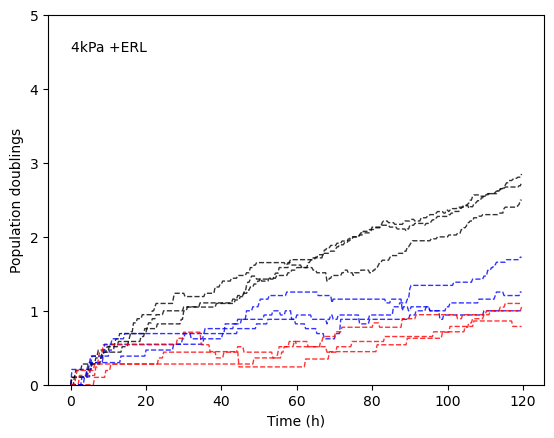

In [89]:
fig,ax = make_fig(cell_counts_di['0'][0], 120, title="4kPa +ERL")
for ii in range(3):
    add_plot(cell_counts_di_4erl['0'][ii], 120, fig, ax, title="Unknown condition", color="black", ls='--')
    add_plot(cell_counts_di_4erl['0.5'][ii], 120, fig, ax, title="Unknown condition", color="blue", ls='--')
    add_plot(cell_counts_di_4erl['5'][ii], 120, fig, ax, title="Unknown condition", color="red", ls='--')
    
# for ii in range(3):
#     add_plot(cell_counts_di_55erl['0'][ii], 120, fig, ax, title="Unknown condition", color="black")
#     add_plot(cell_counts_di_55erl['0.5'][ii], 120, fig, ax, title="Unknown condition", color="blue")
#     add_plot(cell_counts_di_55erl['5'][ii], 120, fig, ax, title="Unknown condition", color="red")
    

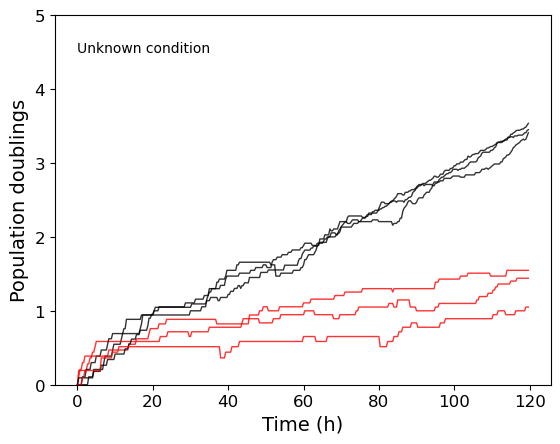

In [231]:
fig,ax = make_fig(cell_counts_di_55erl['0'][0], 120, title="Unknown condition")
for ii in range(3):
    add_plot(cell_counts_di_55erl['0'][ii], 120, fig, ax, title="Unknown condition", color="black")
#     add_plot(cell_counts_di_55erl['0.1'][ii], 120, fig, ax, title="Unknown condition", color="blue")
    add_plot(cell_counts_di_55erl['1'][ii], 120, fig, ax, title="Unknown condition", color="red")

In [294]:
from pathlib import Path
from scipy.signal import savgol_filter
import re
import math
SAVEFILES = False
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)

    
DATADIR = "C:\\Users\\olesk\\ECM_mod_output"


In [295]:
filepaths = os.listdir(DATADIR)
filenames = [f for f in filepaths if re.search('^cell_counts.*csv$', f)]
filepaths = [Path(DATADIR, f) for f in filenames]
filepaths.sort()

In [296]:
def calc_doub(filename):
    tmp = np.loadtxt(filename, delimiter=',')
    
    t = np.arange(0,121)
    new_r = []
    for num in t:
        vals = tmp[tmp[:,0]<=num]
        new_r.append([num, vals[-1,1]])
    
    doubs = []
    for num in t:
        doub = math.log(new_r[num][1]/new_r[0][1])/math.log(2)
        doubs.append([num, doub])
        
    return doubs
    

In [297]:
all_doubs = pd.DataFrame(columns=['Condition','Time','Doub'])
for filename in filepaths:
    doub = calc_doub(filename)
    tmp = [x[1] for x in doub]
    
    split_n = str(filename).split('\\')
    name = split_n[-1].split('.c')[0]
    
    t = np.arange(0,121)
    data = {
        'Condition': [name]*len(t), 
        'Time': t,
        'Doub': tmp}
    tmp_df = pd.DataFrame(data)
    
    all_doubs = pd.concat([all_doubs, tmp_df], ignore_index=True)
    


C:\Users\olesk\AppData\Local\Temp\ipykernel_15652\2067843329.py:16: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [298]:
doub_arr = np.zeros((121,18))
n = 0
for filename in filepaths:
    
    split_n = str(filename).split('\\')
    name = split_n[-1].split('.c')[0]
    
    tmp = all_doubs.loc[all_doubs['Condition'] == name]
    doub_arr[:,n]=tmp['Doub']
    n+=1

    

In [299]:
means=[np.mean(doub_arr[:,0:2],axis=1), np.mean(doub_arr[:,3:5],axis=1), np.mean(doub_arr[:,6:8],axis=1), 
       np.mean(doub_arr[:,9:11],axis=1), np.mean(doub_arr[:,12:14],axis=1), np.mean(doub_arr[:,15:17],axis=1)]
    
stdevs=[np.std(doub_arr[:,0:2],axis=1), np.std(doub_arr[:,3:5],axis=1), np.std(doub_arr[:,6:8],axis=1), 
       np.std(doub_arr[:,9:11],axis=1), np.std(doub_arr[:,12:14],axis=1), np.std(doub_arr[:,15:17],axis=1)]


In [300]:
run_time = 120
all_doubs = np.zeros((360,3))
for ii in range(3):
    cell_count = cell_counts_di_55erl['1'][ii]
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    all_doubs[:,ii] = pop_dubs



In [301]:
mean_treat = np.mean(all_doubs, axis=1)
std_treat = np.std(all_doubs, axis=1)

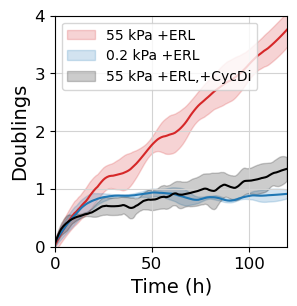

In [302]:
win = 21
pol = 2
size = (3,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = 0
xmax = 120
ymin = 0
ymax = 4

params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

fig, axes = plt.subplots(1, 1, figsize=size)

t = np.arange(0,121)
t1 = np.arange(0, run_time, 1 / 3)
axes.plot(t, savgol_filter(means[5],win,pol), color=c2)
axes.fill_between(t, savgol_filter(means[5] - stdevs[5],win,pol), 
                     savgol_filter(means[5] + stdevs[5],win,pol), color=c2, alpha=0.2, label='55 kPa +ERL')

axes.plot(t, savgol_filter(means[1],win,pol), color=c1)
axes.fill_between(t, savgol_filter(means[1] - stdevs[1],win,pol),
                     savgol_filter(means[1] + stdevs[1],win,pol), color=c1, alpha=0.2, label='0.2 kPa +ERL')

axes.plot(t1, savgol_filter(mean_treat,win,pol), color='black')
axes.fill_between(t1, savgol_filter(mean_treat - std_treat,win,pol),
                     savgol_filter(mean_treat + std_treat,win,pol), color='black', alpha=0.2, label='55 kPa +ERL,+CycDi')


axes.set_xlim([xmin, xmax])
axes.set_ylim([ymin, ymax])

axes.set_xticks([0,50,100])
axes.set_yticks([0,1,2,3,4])
axes.grid(color='lightgray')
axes.set_xlabel('Time (h)')
axes.set_ylabel('Doublings')

axes.legend()



In [303]:

add_plot(cell_counts_di['0'][0], 120, fig, ax, title="Unknown condition", color="black")

NameError: name 'cell_counts_di' is not defined

### CycDi 4kPa ERL

In [304]:
filepath = 'C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_55kpa_erl.json'

In [305]:
fp, ctrl_dip_data, expt_dip_data = calc_resp(filepath, 'cycdi', wells=WELLS)

C:\Users\olesk\AppData\Local\Temp\ipykernel_15652\2966383881.py:26: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning:

invalid value encountered in log



In [306]:
df_params = fit_params_minimal(ctrl_dip_data, expt_dip_data)

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning:

invalid value encountered in log



In [307]:
expt_dip_data

index plate  well_num  dip_rate  \
drug     cell_line dose       well_id                                      
(cycdi,) DS8       (1e-09,)   test__24       0  test        24  0.024274   
                              test__25     274  test        25  0.025834   
                              test__26     598  test        26  0.028538   
                   (1e-08,)   test__48     916  test        48  0.026372   
                              test__49    1207  test        49  0.024869   
                              test__50    1463  test        50  0.025582   
                   (2.5e-08,) test__72    1749  test        72  0.023992   
                              test__73    2034  test        73  0.022652   
                              test__74    2278  test        74  0.026326   
                   (5e-08,)   test__96    2524  test        96  0.022984   
                              test__97    2717  test        97  0.023250   
                              test__98    2962  test        98  0.021964   
                   (7.5e-08,) test__120   3154  test       120  0.019840   
                              test__121   3332  test       121  0.019544   
                              test__122   3526  test       122  0.018477   
                   (1e-07,)   test__144   3708  test       144  0.014266   
                              test__145   3871  test       145  0.020539   
                              test__146   4016  test       146  0.013178   
                   (2.5e-07,) test__168   4175  test       168  0.015060   
                              test__169   4304  test       169  0.010493   
                              test__170   4435  test       170  0.011233   
                   (5e-07,)   test__192   4568  test       192  0.012333   
                              test__193   4686  test       193  0.019408   
                              test__194   4769  test       194  0.013037   
                   (1e-06,)   test__216   4876  test       216  0.007181   
                              test__217   4977  test       217  0.008180   
                              test__218   5062  test       218  0.006147   
                   (2e-06,)   test__240   5126  test       240  0.006242   
                              test__241   5221  test       241  0.010434   
                              test__242   5298  test       242  0.009220   
                   (5e-06,)   test__264   5360  test       264  0.006128   
                              test__265   5436  test       265  0.008143   
                              test__266   5513  test       266  0.010044   
                   (1e-05,)   test__288   5580  test       288 -0.001832   
                              test__289   5643  test       289  0.006971   
                              test__290   5721  test       290  0.010892   

                                         dip_fit_std_err  dip_first_timepoint  \
drug     cell_line dose       well_id                                           
(cycdi,) DS8       (1e-09,)   test__24          0.000113               40.936   
                              test__25          0.000077               15.452   
                              test__26          0.000091               11.839   
                   (1e-08,)   test__48          0.000109               12.642   
                              test__49          0.000120                6.522   
                              test__50          0.000079               15.853   
                   (2.5e-08,) test__72          0.000125               14.950   
                              test__73          0.000168                2.910   
                              test__74          0.000137                2.308   
                   (5e-08,)   test__96          0.000249               36.722   
                              test__97          0.000116               37.826   
                              test__98          0.000199                8.027   
                  

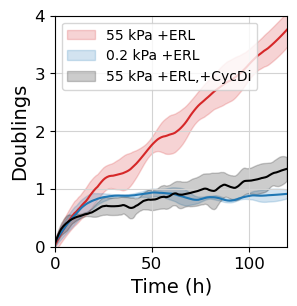

In [308]:
fig

In [148]:
fp['ec50'].iloc[0]

1.0998062659300428e-07

In [309]:
fig = plot_drc(fp)

In [310]:
fig.data[0]

Scatter({
    'hoverinfo': 'all',
    'legendgroup': 'DS8\ncycdi',
    'line': {'color': 'rgb(246, 112, 136)', 'dash': 'solid', 'shape': 'spline', 'width': 3},
    'mode': 'lines',
    'name': 'DS8\ncycdi',
    'showlegend': False,
    'visible': True,
    'x': array([1.0e-10, 1.5e-10, 2.0e-10, 2.5e-10, 3.0e-10, 3.5e-10, 4.0e-10, 4.5e-10,
                5.0e-10, 5.5e-10, 6.0e-10, 6.5e-10, 7.0e-10, 7.5e-10, 8.0e-10, 8.5e-10,
                9.0e-10, 9.5e-10, 1.0e-09, 1.5e-09, 2.0e-09, 2.5e-09, 3.0e-09, 3.5e-09,
                4.0e-09, 4.5e-09, 5.0e-09, 5.5e-09, 6.0e-09, 6.5e-09, 7.0e-09, 7.5e-09,
                8.0e-09, 8.5e-09, 9.0e-09, 9.5e-09, 1.0e-08, 1.5e-08, 2.0e-08, 2.5e-08,
                3.0e-08, 3.5e-08, 4.0e-08, 4.5e-08, 5.0e-08, 5.5e-08, 6.0e-08, 6.5e-08,
                7.0e-08, 7.5e-08, 8.0e-08, 8.5e-08, 9.0e-08, 9.5e-08, 1.0e-07, 1.5e-07,
                2.0e-07, 2.5e-07, 3.0e-07, 3.5e-07, 4.0e-07, 4.5e-07, 5.0e-07, 5.5e-07,
                6.0e-07, 6.5e-07, 7.0e-07, 

In [311]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)
import matplotlib.offsetbox as offsetbox

In [312]:
def plot_dipplt(fig=fig, fp=fp):
    fig1 = plt.figure()
    ax = fig1.add_subplot(1,1,1)
    
    mean_untreated = np.mean(fig.data[2]['y'])
    norm_treated = [num/mean_untreated for num in fig.data[1]['y']]
    
    line, = ax.plot(fig.data[0]['x'], fig.data[0]['y'], color='red')
    pts = ax.scatter(fig.data[1]['x'], norm_treated, color='black')
    
    
    
    ob = offsetbox.AnchoredText(f'EC50: {fp["ec50"].iloc[0]:.2e} M \nIC50: {fp["ic50"].iloc[0]:.2e} M', loc=3)
    # ax.text(1, 0.5, f'EC50: {fp["ec50"].iloc[0]:.2e} M', ha='center')
    ax.add_artist(ob)
    
    ax.set_xlim(1.0e-10, 1.0e-4)
    ax.set_xscale('log')
    ax.xaxis.set_tick_params(labelbottom=False)
#     ax.set_xlabel('CycDi [M]')
    ax.set_ylabel('Relative DIP Rate')
    

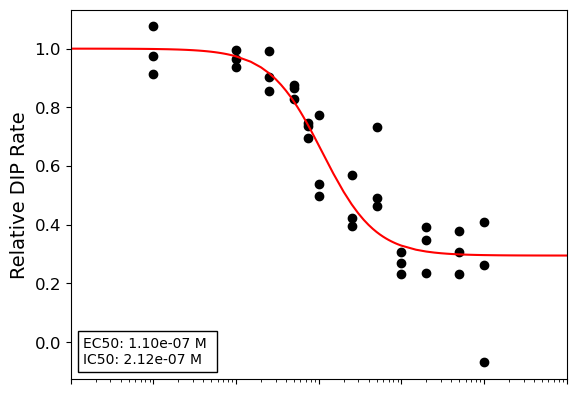

In [313]:
plot_dipplt(fig=fig, fp=fp)

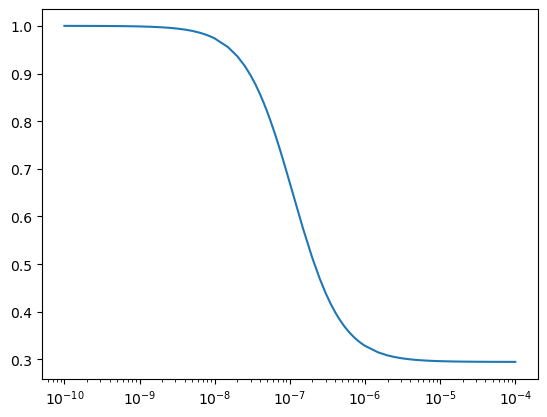

In [109]:
plt.plot(fig.data[0]['x'], fig.data[0]['y'])
# plt.scatter(fig.data[1]['x'], fig.data[1]['y'])
plt.xscale('log')

### CycBi 4kPa ERL

In [14]:
filepath = 'C:\\Users\\olesk\\ECM_mod_output\\cell_counts_bi_4kpa_erl.json'

fp = calc_resp(filepath, 'cycbi', wells=WELLS)

plot_drc(fp)

C:\Users\olesk\AppData\Local\Temp\ipykernel_21408\1520190320.py:26: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning:

invalid value encountered in log

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:224: RuntimeWarning:

invalid value encountered in scalar power



### CycDi 55kPa ERL

In [15]:
filepath = 'C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_55kpa_erl.json'

fp = calc_resp(filepath, 'cycdi', wells=WELLS)

plot_drc(fp)

C:\Users\olesk\AppData\Local\Temp\ipykernel_21408\1520190320.py:26: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning:

invalid value encountered in log



In [256]:
name = filepath.split('\\')[-1].split('.')[0].split('_')[2:]

In [258]:
test = '_'.join(name)
test

'di_4kpa_erl'

In [234]:
all_treats = add_cond(all_treats, cell_counts_di, drug='cycDi')

C:\Users\olesk\AppData\Local\Temp\ipykernel_17972\1520190320.py:26: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [235]:
all_treats

,expt.id,expt.date,plate.name,well,cell.line,time,drug1,drug1.conc,drug1.units,cell.count,upid
0,1,2023-11-21,test,A01,DS8,0.000,cycDi,0.0000,M,11.0,test
1,1,2023-11-21,test,A01,DS8,0.201,cycDi,0.0000,M,12.0,test
2,1,2023-11-21,test,A01,DS8,0.401,cycDi,0.0000,M,13.0,test
3,1,2023-11-21,test,A01,DS8,0.702,cycDi,0.0000,M,14.0,test
4,1,2023-11-21,test,A01,DS8,2.609,cycDi,0.0000,M,15.0,test
...,...,...,...,...,...,...,...,...,...,...,...
4589,1,2023-11-21,test,M03,DS8,116.972,cycDi,0.0001,M,24.0,test
4590,1,2023-11-21,test,M03,DS8,117.692,cycDi,0.0001,M,25.0,test
4591,1,2023-11-21,test,M03,DS8,118.495,cycDi,0.0001,M,25.0,test
4592,1,2023-11-21,test,M03,DS8,119.298,cycDi,0.0001,M,25.0,test


In [236]:
all_treats.to_csv('C:\\Users\\olesk\\ECM_mod_output\\test.csv', index=False)

In [14]:
from thunor.io import read_vanderbilt_hts
hts007 = read_vanderbilt_hts('C:\\Users\\olesk\\ECM_mod_output\\test.csv')

HTS Dataset (1 drugs/combos, 1 cell lines)

In [10]:
from thunor.dip import dip_rates
from thunor.curve_fit import fit_params

In [220]:
hts007

HTS Dataset (1 drugs/combos, 1 cell lines)

In [239]:
ctrl_dip_data, expt_dip_data = dip_rates(hts007)

In [240]:
fp = fit_params(ctrl_dip_data, expt_dip_data)

In [11]:
from thunor.plots import plot_drc, plot_drc_params, plot_time_course, plot_ctrl_dip_by_plate, plot_plate_map

In [242]:
plot_drc(fp)

In [191]:
hts007_file = 'C:\\Users\\olesk\\anaconda3\\envs\\ECM_model\\Lib\\site-packages\\thunor\\hts007.h5'
hts007_filecsv = 'C:\\Users\\olesk\\Downloads\\gkab424_supplemental_files\\Data File S2 - hts007\\hts007.csv'

In [166]:
from thunor.io import read_hdf

In [212]:
hts007c = read_hdf(hts007_file)
#hts007csv = read_vanderbilt_hts(hts007_filecsv)

In [213]:
hts007c

HTS Dataset (27 drugs/combos, 8 cell lines)

In [168]:
hts007r = hts007c.filter(drugs=['cediranib', 'everolimus', 'paclitaxel'])

In [214]:
ctrl_dip_data, expt_dip_data = dip_rates(hts007r)
fp = fit_params(ctrl_dip_data, expt_dip_data)

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning: invalid value encountered in log
  return c + (d - c) / (1 + np.exp(b * (np.log(x) - np.log(e))))
C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:224: RuntimeWarning: invalid value encountered in scalar power
  icN = self.ec50 * (ic_frac / (1 - ic_frac - (emax / e0))) ** (


In [217]:
type(expt_dip_data)

pandas.core.frame.DataFrame